In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import nflreadpy as nfl

import keras
from keras import layers
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, log_loss

keras.utils.set_random_seed(42)
DATA_DIR = Path("../Data/data/processed")


train = pd.read_csv(DATA_DIR / "nfl_train.csv")
validation = pd.read_csv(DATA_DIR / "nfl_validation.csv")
test = pd.read_csv(DATA_DIR / "nfl_test.csv")
train_seasons = train["season"].unique()

print("Rows (train / validation / test):", len(train), len(validation), len(test))

Rows (train / validation / test): 9518 2064 2485


In [3]:
games = nfl.load_schedules(seasons=True).to_pandas()
games = games[(games["game_type"] == "REG") & games["home_score"].notna()].copy()

# includes some team names that no longer exist
# but since their data can still be used for alst 16 LSTM of new-named team, should use (training) 
old_names = {"STL": "LA", "SD": "LAC", "OAK": "LV"}
games["home_team"] = games["home_team"].replace(old_names)
games["away_team"] = games["away_team"].replace(old_names)

In [4]:
# first LSTM run throuhg is going to consist of basic stats similar to Bayesian model
cols = ["season", "week", "game_id", "team", "opponent_team", "is_home",
        "points_for", "points_against"]

# and each single game log is going to be split into a home team game log and an opponent game log
home = games.rename(columns={"home_team": "team", "away_team": "opponent_team",
                             "home_score": "points_for", "away_score": "points_against"})
away = games.rename(columns={"away_team": "team", "home_team": "opponent_team",
                             "away_score": "points_for", "home_score": "points_against"})


log = pd.concat([home.assign(is_home=1)[cols], away.assign(is_home=0)[cols]])
log = log.sort_values(["team", "season", "week"]).reset_index(drop=True)

# with a win column even though I think I might just use point diff we shall see
log["win"] = (log["points_for"] > log["points_against"]).astype(int)

In [ ]:
# input features = cols - (season, week, id, team (implicit)) 
step_features = ["points_for", "points_against", "win", "is_home"]
N_MAX = 16

# i think that scaled mu=0 sigma=1 is the way to go here instead of raw points for/against data
scaler = StandardScaler().fit(log.loc[log["season"].isin(train_seasons), step_features])
log[step_features] = scaler.transform(log[step_features])

by_team = log.groupby("team")[step_features]

# these 16 weeks worth of data will be our LSTM lag
lags = pd.concat([by_team.shift(k).add_suffix(f"_lag{k}") for k in range(1, N_MAX + 1)], axis=1)
log = pd.concat([log, lags], axis=1)

#test lag table/matrix with my chargers 
log.loc[log["team"] == "LAC", ["season", "week", "points_for", "points_for_lag1", "points_for_lag2"]].head(6)

,season,week,points_for,points_for_lag1,points_for_lag2
7553,1999,2,1.192868,NaN,NaN
7554,1999,3,-0.263280,1.192868,NaN
7555,1999,4,-0.069127,-0.263280,1.192868
7556,1999,5,-0.166203,-0.069127,-0.263280
7557,1999,6,-0.845739,-0.166203,-0.069127
7558,1999,7,-1.816505,-0.845739,-0.166203


In [ ]:
# for a given prediction we must find the home/opp lag cols 
lag_cols = list(lags.columns)
team_hist = log[["game_id", "team"] + lag_cols]
opp_hist = team_hist.rename(columns={"team": "opponent_team", **{c: "opp_" + c for c in lag_cols}})


def attach(split):
    out = (split.merge(team_hist, on=["game_id", "team"], validate="one_to_one")
                .merge(opp_hist, on=["game_id", "opponent_team"], validate="one_to_one"))
    # ts been somtimes outputting only 15 games i think i messed up the bye?
    assert len(out) == len(split), "not 16 games"
    return out


train, validation, test = attach(train), attach(validation), attach(test)
y_train, y_val, y_test = train["win"].to_numpy(), validation["win"].to_numpy(), test["win"].to_numpy()

# to input cols into LSTM need array of rows, N games, features
# and match home team kth last game with opponent kth last game for continuity
def make_inputs(df, n):
    # oldest game first
    cols = [f"{side}{f}_lag{k}" for k in range(n, 0, -1)          
            for side in ["", "opp_"] for f in step_features]
    # i think some games are missing from data
    # i dont want to handel them like bye weeks where we skip
    # so i think should do what Jason did and pretend they were league avg game
    # could also make them avg of teams last N games but idk
    X = df[cols].fillna(0).to_numpy("float32").reshape(len(df), n, 2 * len(step_features))
    home = df[["is_home"]].to_numpy("float32")
    return [X, home]

In [7]:
def make_model(n, units=16, dropout=0.2):
    keras.utils.set_random_seed(42)
    seq_in = keras.Input(shape=(n, 2 * len(step_features)))
    home_in = keras.Input(shape=(1,))

    x = layers.LSTM(units)(seq_in)
    x = layers.Dropout(dropout)(x)
    x = layers.Concatenate()([x, home_in])
    output = layers.Dense(1, activation="sigmoid")(x)

    model = keras.Model([seq_in, home_in], output)
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model


make_model(8).summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 8, 8)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 16)        │      1,600 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 16)        │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_1       │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 17)        │          0 │ dropout[0][0],    │
│ (Concatenate)       │                   │            │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1)         │         18 │ concatenate[0][0] │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,618 (6.32 KB)

 Trainable params: 1,618 (6.32 KB)

 Non-trainable params: 0 (0.00 B)

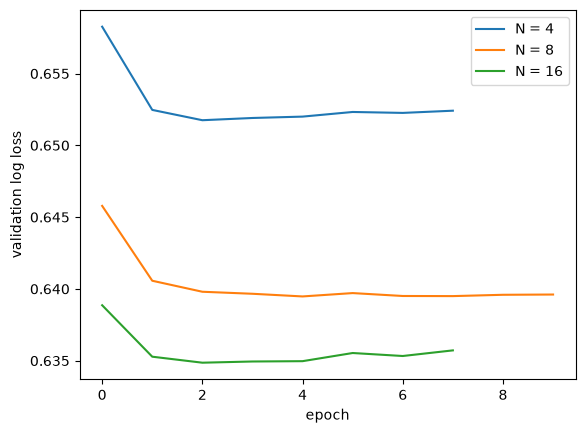

,n_games,best_epoch,val_log_loss,val_accuracy
0,16,3,0.6349,0.6453
1,8,5,0.6395,0.6294
2,4,3,0.6517,0.6206


In [8]:
models, histories, rows = {}, {}, []
for n in [4, 8, 16]:
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    models[n] = make_model(n)
    histories[n] = models[n].fit(make_inputs(train, n), y_train,
                                 validation_data=(make_inputs(validation, n), y_val),
                                 epochs=60, batch_size=64, callbacks=[stop], verbose=0)
    val_loss = histories[n].history["val_loss"]
    best = int(np.argmin(val_loss))
    rows.append({"n_games": n, "best_epoch": best + 1, "val_log_loss": val_loss[best],
                 "val_accuracy": histories[n].history["val_accuracy"][best]})

for n, h in histories.items():
    plt.plot(h.history["val_loss"], label=f"N = {n}")
plt.xlabel("epoch")
plt.ylabel("validation log loss")
plt.legend()
plt.show()

tuning = pd.DataFrame(rows).sort_values("val_log_loss").reset_index(drop=True)
tuning.round(4)

In [9]:
best_n = int(tuning.loc[0, "n_games"])
print("picked N =", best_n)

test["prob"] = models[best_n].predict(make_inputs(test, best_n), verbose=0).ravel()
test["pred"] = (test["prob"] > 0.5).astype(int)

bayes = pd.read_csv(DATA_DIR / "predictions_bayes.csv")[["game_id", "team", "prob"]]
mlp = pd.read_csv(DATA_DIR / "predictions_mlp.csv")[["game_id", "team", "prob"]]
both = (test.merge(bayes, on=["game_id", "team"], suffixes=("", "_bayes"), validate="one_to_one")
            .merge(mlp, on=["game_id", "team"], suffixes=("", "_mlp"), validate="one_to_one"))

comparison = pd.DataFrame([
    {"model": f"LSTM (N = {best_n})", "accuracy": accuracy_score(both["win"], both["prob"] > 0.5),
     "log_loss": log_loss(both["win"], both["prob"])},
    {"model": "Bayesian (head-to-head + home)",
     "accuracy": accuracy_score(both["win"], both["prob_bayes"] > 0.5),
     "log_loss": log_loss(both["win"], both["prob_bayes"])},
    {"model": "MLP", "accuracy": accuracy_score(both["win"], both["prob_mlp"] > 0.5),
     "log_loss": log_loss(both["win"], both["prob_mlp"])},
    {"model": "Always pick the home team",
     "accuracy": accuracy_score(both["win"], both["is_home"]), "log_loss": np.nan},
])
print("test rows:", len(both))
print("same pick as Bayesian:", round(((both["prob"] > 0.5) == (both["prob_bayes"] > 0.5)).mean(), 3))
comparison.round(4)

picked N = 16
test rows: 2485
same pick as Bayesian: 0.839


/var/folders/c4/plk1ly7j6x54y3yn65pc9_8r0000gn/T/ipykernel_61338/2585256664.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  test["prob"] = models[best_n].predict(make_inputs(test, best_n), verbose=0).ravel()
/var/folders/c4/plk1ly7j6x54y3yn65pc9_8r0000gn/T/ipykernel_61338/2585256664.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  test["pred"] = (test["prob"] > 0.5).astype(int)


,model,accuracy,log_loss
0,LSTM (N = 16),0.6410,0.6348
1,Bayesian (head-to-head + home),0.6274,0.6464
2,MLP,0.6149,0.6481
3,Always pick the home team,0.5416,NaN
